In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

import os
from pathlib import Path



In [6]:

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

print("All Libraries Imported Successfully!")

All Libraries Imported Successfully!


In [7]:
file_path = Path("telco_customer_churn.csv")

if not file_path.exists():
    raise FileNotFoundError(
        f"Dataset not found: {file_path.resolve()}"
    )

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")


Dataset loaded successfully!


In [8]:
# dataset information
print("Dataset Information:")

df.info()

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null 

In [59]:
print("Dataset Shape:", df.shape)

print("\nFirst 5 Records:")
print(df.head())

print("\nLast 5 Records:")
print(df.tail())


Dataset Shape: (7043, 21)

First 5 Records:
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity OnlineBackup  \
0  No phone service             DSL             No          Yes   
1                No             DSL            Yes           No   
2                No             DSL            Yes          Yes   
3  No phone service             DSL            Yes           No   
4                No     Fiber optic             No           No   

  DeviceProtection TechSupport StreamingTV StreamingMovies        Contra

In [60]:
print("Column Names:\n")

for column in df.columns:
    print(column)

Column Names:

customerID
gender
SeniorCitizen
Partner
Dependents
tenure
PhoneService
MultipleLines
InternetService
OnlineSecurity
OnlineBackup
DeviceProtection
TechSupport
StreamingTV
StreamingMovies
Contract
PaperlessBilling
PaymentMethod
MonthlyCharges
TotalCharges
Churn


In [9]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [62]:
df.describe(include="all")

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7043,7043,7043.000000,7043,7043,7043.000000,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043.000000,7043,7043
unique,7043,2,NaN,2,2,NaN,2,3,3,3,3,3,3,3,3,3,2,4,NaN,6531,2
top,7590-VHVEG,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,20.2,No
freq,1,3555,NaN,3641,4933,NaN,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,NaN,11,5174
mean,NaN,NaN,0.162147,NaN,NaN,32.371149,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.761692,NaN,NaN
std,NaN,NaN,0.368612,NaN,NaN,24.559481,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.090047,NaN,NaN
min,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,NaN,NaN
25%,NaN,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.500000,NaN,NaN
50%,NaN,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350000,NaN,NaN
75%,NaN,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.850000,NaN,NaN


In [63]:
# missing values

missing_valuese = df.isnull().sum()

print("Missing Values:")
print(missing_valuese[missing_valuese > 0])

Missing Values:
Series([], dtype: int64)


In [64]:
# duplicate rows

print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


In [65]:
# duplicate customer IDs

print(
    "Duplicate Customer IDs:",
    df["customerID"].duplicated().sum()
)

Duplicate Customer IDs: 0


In [66]:
# target variable distribution
print(df["Churn"].value_counts())

print("\nChurn Percentage:")
print(df["Churn"].value_counts(normalize=True) * 100)

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn Percentage:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


In [67]:
# dataset dimensions
print("Dataset shape:", df.shape)

Dataset shape: (7043, 21)


In [68]:
print("\nColumns:")
print(df.columns.tolist())


Columns:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [69]:
print("\nData Types:")
print(df.dtypes)


Data Types:
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object


In [70]:
# remove unwanted spaces from column names

df.columns = df.columns.str.strip()

print(df.columns.tolist())

['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [71]:
# remove extra spaces from text columns
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

print("Text cleaning completed!")


Text cleaning completed!


/var/folders/zc/4dlsxpp92h34m53lllv_m3pr0000gn/T/ipykernel_1696/2523890565.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include="object").columns:


In [72]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

print(df["TotalCharges"].dtypes)

float64


In [73]:
# missing values analyze

missing_report = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (
        df.isnull().sum() / len(df)
    )* 100
    
})

missing_report = missing_report[
    missing_report["Missing_Count"] > 0
]

print(missing_report)

              Missing_Count  Missing_Percentage
TotalCharges             11            0.156183


In [74]:
# missing values ko handle krna

numeric_columns = df.select_dtypes(
    include=np.number
).columns.tolist()

categorical_columns = df.select_dtypes(
    include="object"
).columns.tolist()

print("Numeric Columns:", numeric_columns)
print("\nCategorical Columns:", categorical_columns)

Numeric Columns: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical Columns: ['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn']


/var/folders/zc/4dlsxpp92h34m53lllv_m3pr0000gn/T/ipykernel_1696/3338955183.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(


In [75]:
# missing values fill karna 
for col in numeric_columns:
    df[col] = df[col].fillna(df[col].median())

# categorical columns
for col in categorical_columns:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(
            df[col].mode()[0]
        )

print("Missing values handled !")

Missing values handled !


In [76]:
print("Duplicate Rows:", df.duplicated().sum())
print("Duplicate IDs:", df["customerID"].duplicated().sum())

Duplicate Rows: 0
Duplicate IDs: 0


In [77]:
print(df["Churn"].value_counts(dropna=False))

Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [78]:
print("Unique Churn Values:")

print(df["Churn"].unique())

Unique Churn Values:
<ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str


In [79]:
# data validation report

validation_report = {
    "Total Rows": len(df),
    "Total Columns": df.shape[1],
    "Missing Values": df.isnull().sum().sum(),
    "Duplicate Rows": df.duplicated().sum(),
    "Duplicate Customer IDs": df["customerID"].duplicated().sum(),
    "Target Missing": df["Churn"].isnull().sum()
}

for key, value in validation_report.items():
    print(f"{key}: {value}")

Total Rows: 7043
Total Columns: 21
Missing Values: 0
Duplicate Rows: 0
Duplicate Customer IDs: 0
Target Missing: 0


In [80]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

PROCESSED_PATH = (
    PROJECT_ROOT / "data" / "processed"
)

PROCESSED_PATH.mkdir(
    parents=True,
    exist_ok=True
)

df.to_csv(
    PROCESSED_PATH / "telco_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [81]:
# churn distributio analysis
churn_counts = df["Churn"].value_counts()

print(churn_counts)

Churn
No     5174
Yes    1869
Name: count, dtype: int64


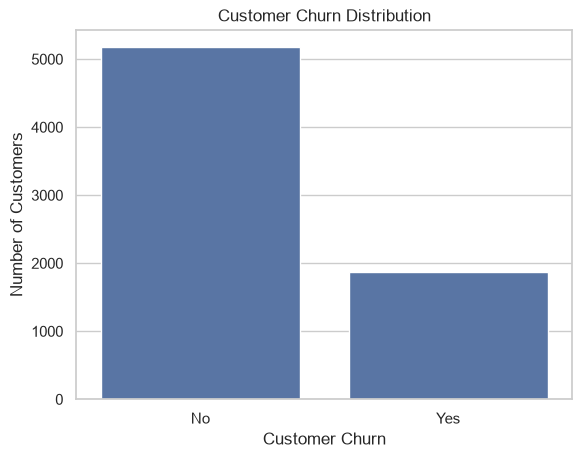

In [82]:
# graph:
plt.Figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Churn"
)

plt.title("Customer Churn Distribution")
plt.xlabel("Customer Churn")
plt.ylabel("Number of Customers")

plt.show()

In [83]:
# churn percentage analysis
churn_percentage = (
    df["Churn"].value_counts(normalize=True) * 100
)

print(churn_percentage)

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


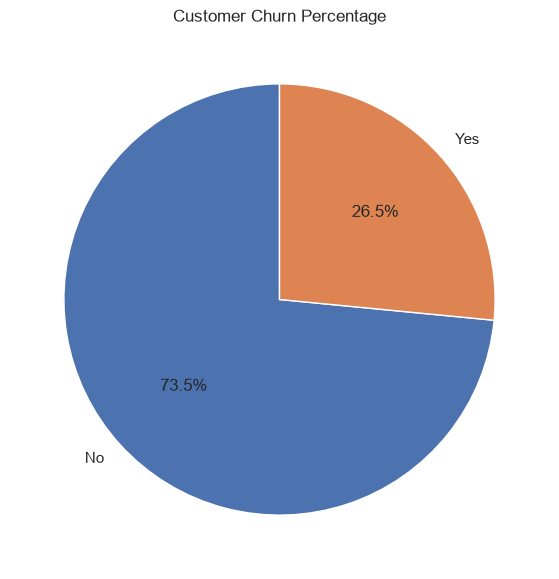

In [84]:
plt.figure(figsize=(7, 7))

plt.pie(
    churn_percentage,
    labels=churn_percentage.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Customer Churn Percentage")

plt.show()

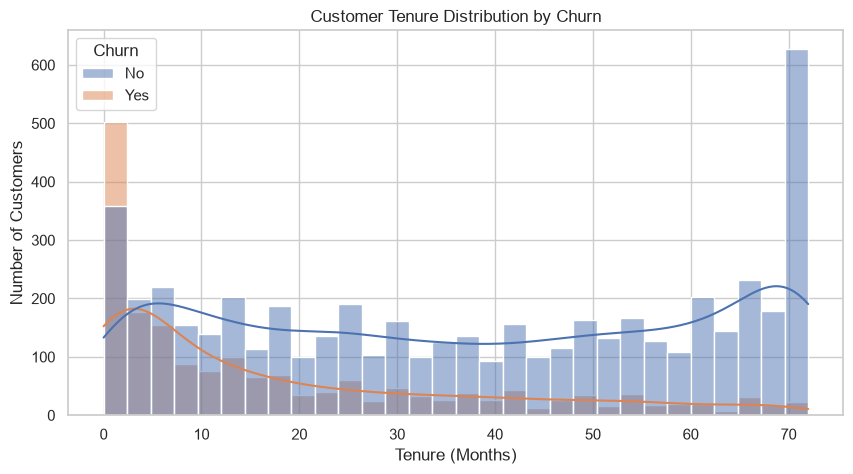

In [85]:
# tenure analysis
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="tenure",
    hue="Churn",
    bins=30,
    kde=True
)

plt.title("Customer Tenure Distribution by Churn")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")

plt.show()

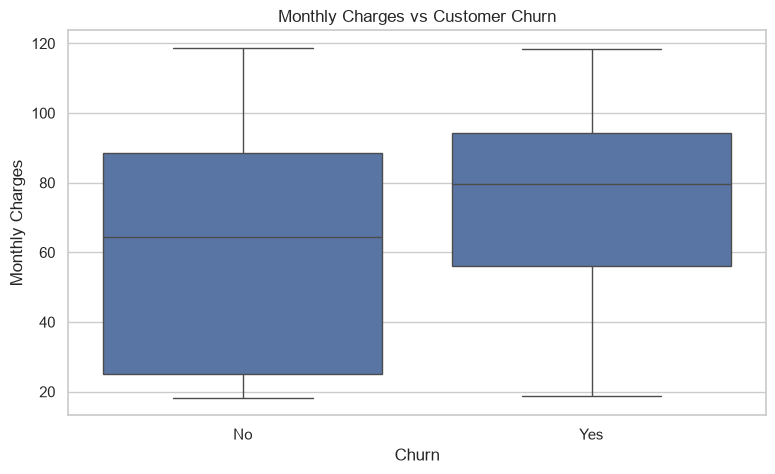

In [86]:
# monthly charges analysis
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges vs Customer Churn")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.show()

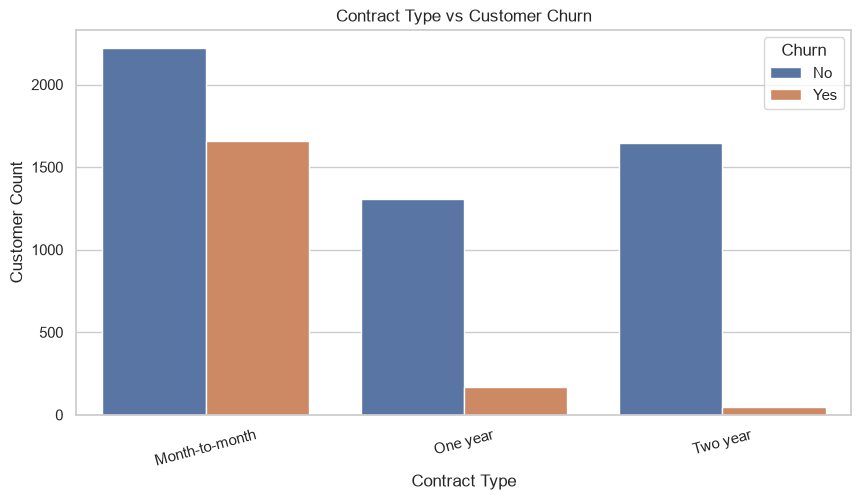

In [87]:
# contract type analysis
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="Contract",
    hue="Churn"
)

plt.title("Contract Type vs Customer Churn")
plt.xlabel("Contract Type")
plt.ylabel("Customer Count")

plt.xticks(rotation=15)

plt.show()

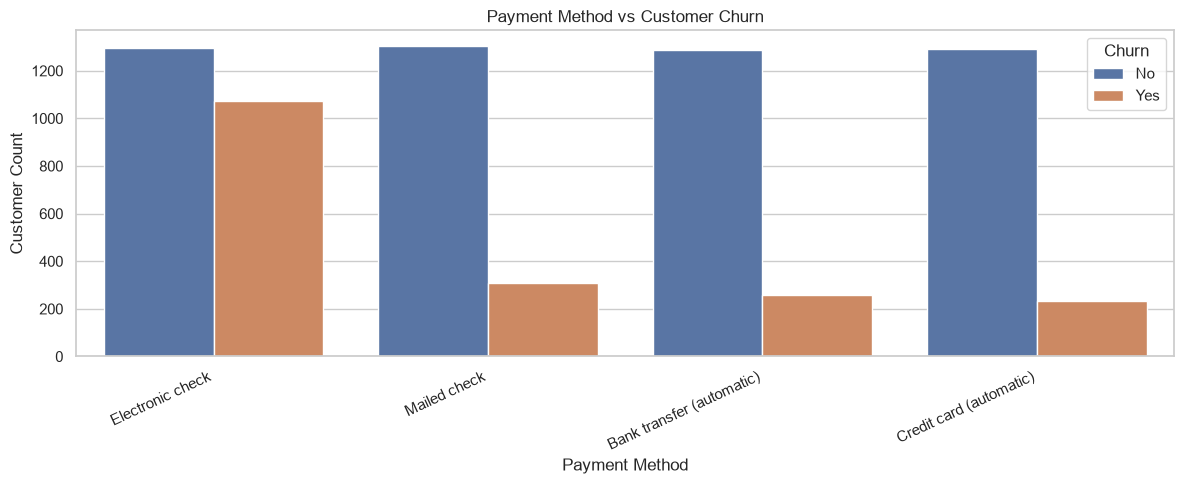

In [88]:
# payment method analysis
plt.figure(figsize=(12, 5))

sns.countplot(
    data=df,
    x="PaymentMethod",
    hue="Churn"
)

plt.title("Payment Method vs Customer Churn")
plt.xlabel("Payment Method")
plt.ylabel("Customer Count")

plt.xticks(rotation=25, ha="right")

plt.tight_layout()
plt.show()

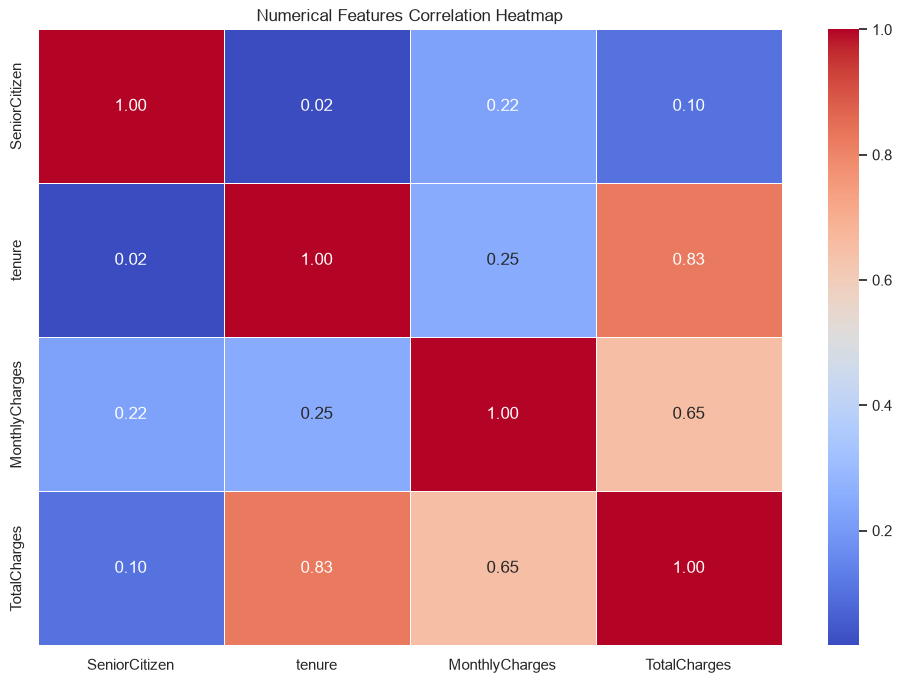

In [89]:
# correlation heatmap
numerical_df = df.select_dtypes(
    include=np.number
)

correlation_matrix = numerical_df.corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Numerical Features Correlation Heatmap")

plt.show()

In [90]:
# churn rate by contract
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

print(contract_churn)

Churn                  No        Yes
Contract                            
Month-to-month  57.290323  42.709677
One year        88.730482  11.269518
Two year        97.168142   2.831858


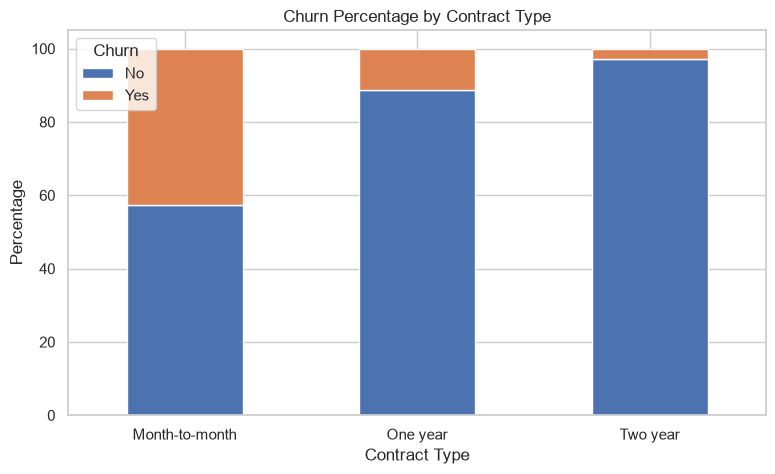

In [91]:
# graph
contract_churn.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)

plt.title("Churn Percentage by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Percentage")

plt.legend(title="Churn")
plt.xticks(rotation=0)

plt.show()

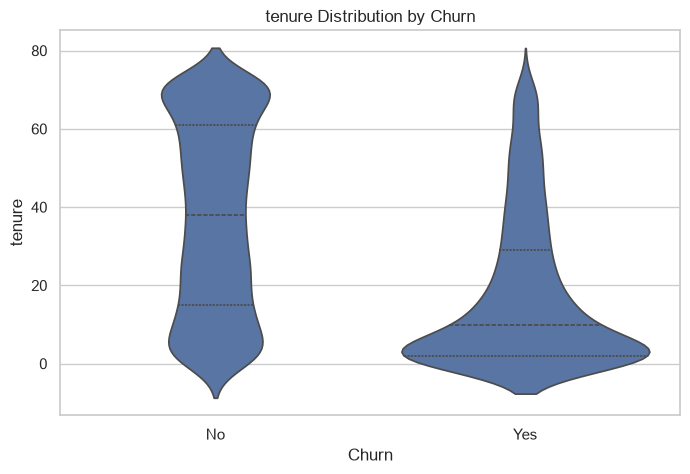

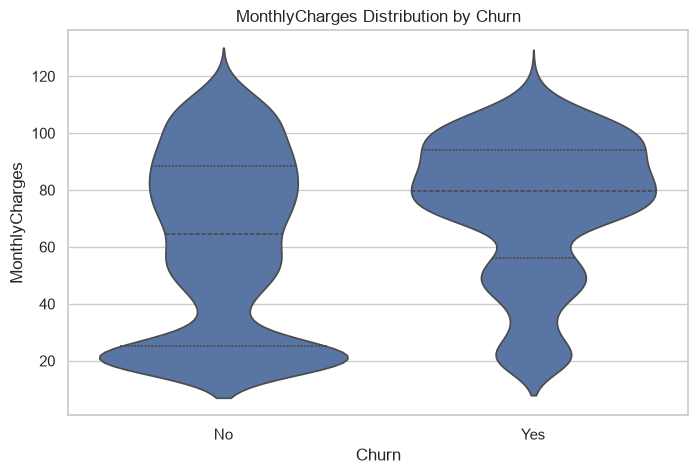

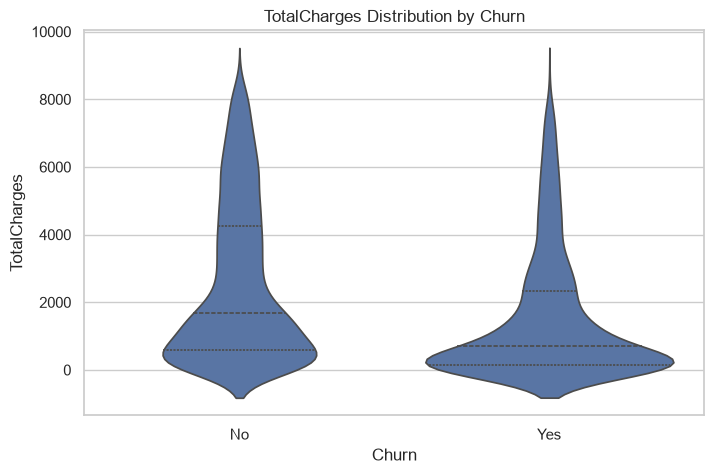

In [92]:
# numerical features comparison

features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

for col in features:

    plt.figure(figsize=(8, 5))

    sns.violinplot(
        data=df,
        x="Churn",
        y=col,
        inner="quartile"
    )

    plt.title(f"{col} Distribution by Churn")
    plt.show()

In [106]:
# Descriptive Statistics

print(df[[
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]].describe())

            tenure  MonthlyCharges  TotalCharges
count  7043.000000     7043.000000   7043.000000
mean     32.371149       64.761692   2281.916928
std      24.559481       30.090047   2265.270398
min       0.000000       18.250000     18.800000
25%       9.000000       35.500000    402.225000
50%      29.000000       70.350000   1397.475000
75%      55.000000       89.850000   3786.600000
max      72.000000      118.750000   8684.800000


In [107]:
print("Monthly Charges Mode:",
      df["MonthlyCharges"].mode()[0])

print("\nChurn Percentage:")
print(df["Churn"].value_counts(normalize=True) * 100)

Monthly Charges Mode: 20.05

Churn Percentage:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


In [93]:

# Create contingency table

contingency_table = pd.crosstab(
    df["Contract"],
    df["Churn"]
)

print(contingency_table)

Churn             No   Yes
Contract                  
Month-to-month  2220  1655
One year        1307   166
Two year        1647    48


In [94]:
from scipy.stats import chi2_contingency

In [95]:
chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

print("Chi-Square Statistic:", chi2)
print("P-Value:", p_value)
print("Degrees of Freedom:", dof)

if p_value < 0.05:
    print("Result: Significant association found.")
else:
    print("Result: No significant association found.")

Chi-Square Statistic: 1184.5965720837926
P-Value: 5.863038300673391e-258
Degrees of Freedom: 2
Result: Significant association found.


In [96]:
import pandas as pd
from scipy.stats import chi2_contingency
# Payment Method vs Churn


payment_table = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"]
)

chi2_payment, p_payment, dof_payment, expected_payment = chi2_contingency(payment_table)

print("Chi-Square:", chi2_payment)
print("P-Value:", p_payment)

Chi-Square: 648.1423274814
P-Value: 3.6823546520097993e-140


In [102]:
from scipy.stats import ttest_ind

# Churned customers
churned = df[df["Churn"] == "Yes"]["MonthlyCharges"]

# Customers who did not churn
not_churned = df[df["Churn"] == "No"]["MonthlyCharges"]

# Calculate average
print("Churned Average:", churned.mean())
print("Retained Average:", not_churned.mean())

# Compare both groups
t_stat, p_value = ttest_ind(
    churned,
    not_churned,
    equal_var=False
)

print("P-Value:", p_value)

if p_value < 0.05:
    print("Significant difference found.")
else:
    print("No significant difference found.")

Churned Average: 74.44133226324237
Retained Average: 61.26512369540008
P-Value: 8.592449331547065e-73
Significant difference found.


In [105]:
results = pd.DataFrame({

    "Test": [
        "Contract vs Churn",
        "Payment Method vs Churn",
        "Monthly Charges vs Churn",
        "Tenure vs Churn"
    ],

    "P_Value": [
        p_value,
        p_payment,
        p_value_t,
        p_value_u
    ]
})

results["Significant"] = np.where(
    results["P_Value"] < 0.05,
    "Yes",
    "No"
)

print(results)

                       Test        P_Value Significant
0         Contract vs Churn   8.592449e-73         Yes
1   Payment Method vs Churn  3.682355e-140         Yes
2  Monthly Charges vs Churn   8.592449e-73         Yes
3           Tenure vs Churn  2.419636e-208         Yes


In [109]:
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=[
        "New Customer",
        "Short-Term",
        "Medium-Term",
        "Long-Term"
    ]
)

print(df[["tenure", "TenureGroup"]].head(10))

   tenure   TenureGroup
0       1  New Customer
1      34   Medium-Term
2       2  New Customer
3      45   Medium-Term
4       2  New Customer
5       8  New Customer
6      22    Short-Term
7      10  New Customer
8      28   Medium-Term
9      62     Long-Term


In [110]:
service_columns = [
    "PhoneService",
    "MultipleLines",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies"
]

# Count only services marked as Yes
df["TotalServices"] = (
    df[service_columns]
    .eq("Yes")
    .sum(axis=1)
)

print(
    df[["customerID", "TotalServices", "Churn"]]
    .head(10)
)

   customerID  TotalServices Churn
0  7590-VHVEG              1    No
1  5575-GNVDE              3    No
2  3668-QPYBK              3   Yes
3  7795-CFOCW              3    No
4  9237-HQITU              1   Yes
5  9305-CDSKC              5   Yes
6  1452-KIOVK              4    No
7  6713-OKOMC              1    No
8  7892-POOKP              6   Yes
9  6388-TABGU              3    No


In [111]:
print(
    df[[
        "customerID",
        "tenure",
        "TenureGroup",
        "TotalServices",
        "MonthlyCharges",
        "Churn"
    ]].head(10)
)

   customerID  tenure   TenureGroup  TotalServices  MonthlyCharges Churn
0  7590-VHVEG       1  New Customer              1           29.85    No
1  5575-GNVDE      34   Medium-Term              3           56.95    No
2  3668-QPYBK       2  New Customer              3           53.85   Yes
3  7795-CFOCW      45   Medium-Term              3           42.30    No
4  9237-HQITU       2  New Customer              1           70.70   Yes
5  9305-CDSKC       8  New Customer              5           99.65   Yes
6  1452-KIOVK      22    Short-Term              4           89.10    No
7  6713-OKOMC      10  New Customer              1           29.75    No
8  7892-POOKP      28   Medium-Term              6          104.80   Yes
9  6388-TABGU      62     Long-Term              3           56.15    No


In [113]:
# categorical columns identify
categorical_columns = df.select_dtypes(
    include="object"
).columns.tolist()

print("Categorical Columns:")
print(categorical_columns)

Categorical Columns:
['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn']


/var/folders/zc/4dlsxpp92h34m53lllv_m3pr0000gn/T/ipykernel_1696/3394885987.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(


In [114]:
# categorical columns values check krna 
for col in categorical_columns:
    print("\nColumn:", col)
    print(df[col].unique())


Column: customerID
<ArrowStringArray>
['7590-VHVEG', '5575-GNVDE', '3668-QPYBK', '7795-CFOCW', '9237-HQITU',
 '9305-CDSKC', '1452-KIOVK', '6713-OKOMC', '7892-POOKP', '6388-TABGU',
 ...
 '9767-FFLEM', '0639-TSIQW', '8456-QDAVC', '7750-EYXWZ', '2569-WGERO',
 '6840-RESVB', '2234-XADUH', '4801-JZAZL', '8361-LTMKD', '3186-AJIEK']
Length: 7043, dtype: str

Column: gender
<ArrowStringArray>
['Female', 'Male']
Length: 2, dtype: str

Column: Partner
<ArrowStringArray>
['Yes', 'No']
Length: 2, dtype: str

Column: Dependents
<ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str

Column: PhoneService
<ArrowStringArray>
['No', 'Yes']
Length: 2, dtype: str

Column: MultipleLines
<ArrowStringArray>
['No phone service', 'No', 'Yes']
Length: 3, dtype: str

Column: InternetService
<ArrowStringArray>
['DSL', 'Fiber optic', 'No']
Length: 3, dtype: str

Column: OnlineSecurity
<ArrowStringArray>
['No', 'Yes', 'No internet service']
Length: 3, dtype: str

Column: OnlineBackup
<ArrowStringArray>
['Yes', 'No

In [115]:
# Target variable
y = df["Churn"]

# Input features
X = df.drop(
    columns=["Churn", "customerID"]
)

print("X Shape:", X.shape)
print("y Shape:", y.shape)

X Shape: (7043, 21)
y Shape: (7043,)


In [116]:
numerical_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'TotalServices']

Categorical Features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TenureGroup']


/var/folders/zc/4dlsxpp92h34m53lllv_m3pr0000gn/T/ipykernel_1696/407092955.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


In [117]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(
    sparse_output=False,
    handle_unknown="ignore"
)

encoded_data = encoder.fit_transform(
    df[["Contract"]]
)

encoded_df = pd.DataFrame(
    encoded_data,
    columns=encoder.get_feature_names_out(["Contract"]),
    index=df.index
)

print(encoded_df.head())

   Contract_Month-to-month  Contract_One year  Contract_Two year
0                      1.0                0.0                0.0
1                      0.0                1.0                0.0
2                      1.0                0.0                0.0
3                      0.0                1.0                0.0
4                      1.0                0.0                0.0


In [118]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [120]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),

        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

In [121]:
# pipline
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing Pipeline Created Successfully!")

Preprocessing Pipeline Created Successfully!


In [122]:
from sklearn.model_selection import train_test_split

# Input features
X = df.drop(
    columns=["Churn", "customerID"]
)

# Target variable
y = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Data: (5634, 21)
Testing Data: (1409, 21)
Training Target: (5634,)
Testing Target: (1409,)


In [123]:
# data leakage prevention
# Learn transformations from training data
X_train_processed = preprocessor.fit_transform(X_train)

# Apply learned transformations to test data
X_test_processed = preprocessor.transform(X_test)

print("Processed Training Shape:", X_train_processed.shape)
print("Processed Testing Shape:", X_test_processed.shape)

Processed Training Shape: (5634, 50)
Processed Testing Shape: (1409, 50)


In [124]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score

In [126]:
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

In [127]:
logistic_model.fit(
    X_train,
    y_train
)

print("Logistic Regression Model Trained Successfully!")

Logistic Regression Model Trained Successfully!


In [128]:
# prediction 
y_pred = logistic_model.predict(X_test)

print("Predictions:")
print(y_pred[:20])

Predictions:
[0 1 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 1 0 0]


In [129]:
# accaracy calculate krna
accuracy = accuracy_score(
    y_test,
    y_pred
)

print("Logistic Regression Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100, "%")

Logistic Regression Accuracy: 0.7984386089425124
Accuracy Percentage: 79.84386089425124 %


In [130]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_test,
    y_pred
)

print(cm)

[[931 104]
 [180 194]]


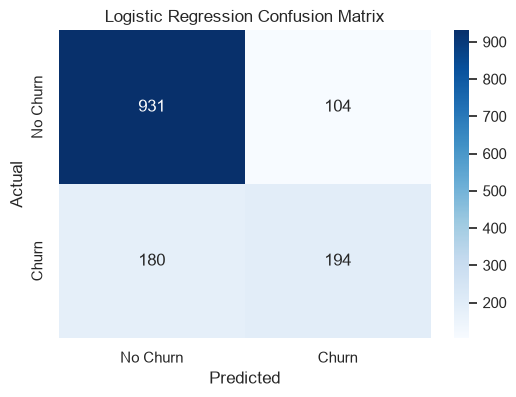

In [131]:
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression Confusion Matrix")

plt.show()

In [132]:
# precision
from sklearn.metrics import precision_score

precision = precision_score(
    y_test,
    y_pred
)

print("Precision:", precision)
print("Precision Percentage:", precision * 100, "%")

Precision: 0.6510067114093959
Precision Percentage: 65.1006711409396 %


In [133]:
# recall
from sklearn.metrics import recall_score

recall = recall_score(
    y_test,
    y_pred
)

print("Recall:", recall)
print("Recall Percentage:", recall * 100, "%")

Recall: 0.5187165775401069
Recall Percentage: 51.87165775401069 %


In [134]:
# F1 score
from sklearn.metrics import f1_score

f1 = f1_score(
    y_test,
    y_pred
)

print("F1-Score:", f1)

F1-Score: 0.5773809523809523


In [135]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("Precision:", precision_score(y_test, y_pred))

print("Recall:", recall_score(y_test, y_pred))

print("F1-Score:", f1_score(y_test, y_pred))

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["No Churn", "Churn"]
    )
)

Accuracy: 0.7984386089425124
Precision: 0.6510067114093959
Recall: 0.5187165775401069
F1-Score: 0.5773809523809523

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.84      0.90      0.87      1035
       Churn       0.65      0.52      0.58       374

    accuracy                           0.80      1409
   macro avg       0.74      0.71      0.72      1409
weighted avg       0.79      0.80      0.79      1409



In [136]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

In [137]:
y_probability = logistic_model.predict_proba(X_test)[:, 1]

print(y_probability[:10])

[0.04120895 0.73524829 0.05259576 0.33456727 0.0245014  0.54470278
 0.38295439 0.10849568 0.00475632 0.31532922]


In [138]:
# ROC curve
fpr, tpr, thresholds = roc_curve(
    y_test,
    y_probability
)

auc_score = roc_auc_score(
    y_test,
    y_probability
)

print("AUC Score:", auc_score)

AUC Score: 0.84211682037769


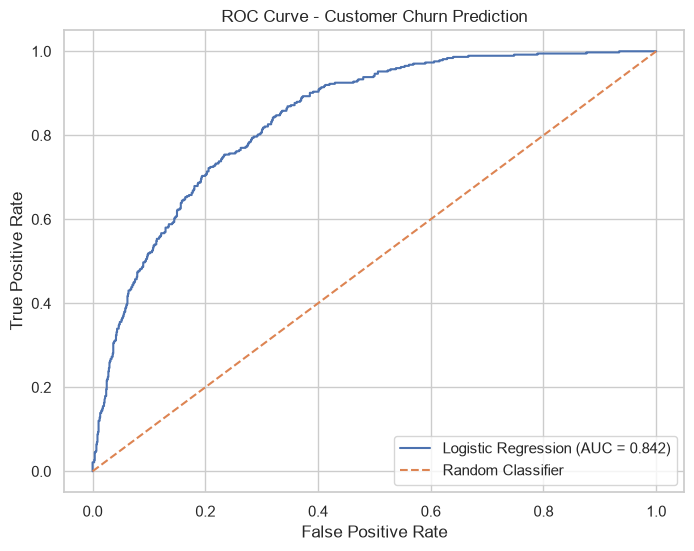

In [139]:
# graph
plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {auc_score:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve - Customer Churn Prediction")

plt.legend()
plt.show()

In [140]:
# New threshold
threshold = 0.30

# Convert probabilities into predictions
y_pred_tuned = (
    y_probability >= threshold
).astype(int)

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

print("Threshold:", threshold)

print("Precision:", precision_score(
    y_test, y_pred_tuned
))

print("Recall:", recall_score(
    y_test, y_pred_tuned
))

print("F1-Score:", f1_score(
    y_test, y_pred_tuned
))

Threshold: 0.3
Precision: 0.5260223048327137
Recall: 0.7566844919786097
F1-Score: 0.6206140350877193


In [141]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline

# Decision Tree Model
decision_tree_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=5,
        min_samples_split=20,
        min_samples_leaf=10,
        class_weight="balanced",
        random_state=42
    ))
])

# Model training
decision_tree_model.fit(X_train, y_train)

# Prediction
y_pred_dt = decision_tree_model.predict(X_test)

print("Decision Tree Model Trained Successfully!")

Decision Tree Model Trained Successfully!


In [142]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("Decision Tree Accuracy:",
      accuracy_score(y_test, y_pred_dt))

print("Decision Tree Precision:",
      precision_score(y_test, y_pred_dt))

print("Decision Tree Recall:",
      recall_score(y_test, y_pred_dt))

print("Decision Tree F1-Score:",
      f1_score(y_test, y_pred_dt))

print("\nClassification Report:\n")

print(classification_report(
    y_test,
    y_pred_dt,
    target_names=["No Churn", "Churn"]
))

Decision Tree Accuracy: 0.7551454932576295
Decision Tree Precision: 0.527001862197393
Decision Tree Recall: 0.7566844919786097
Decision Tree F1-Score: 0.6212952799121844

Classification Report:

              precision    recall  f1-score   support

    No Churn       0.90      0.75      0.82      1035
       Churn       0.53      0.76      0.62       374

    accuracy                           0.76      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.76      0.77      1409



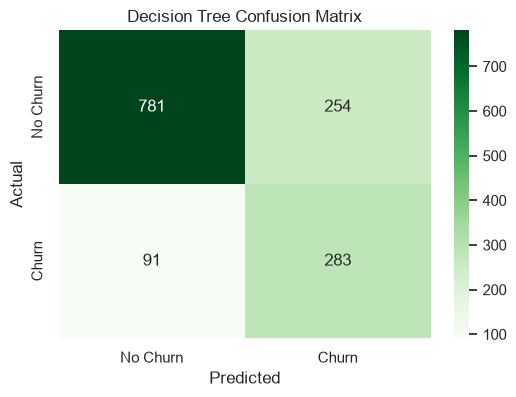

In [143]:
from sklearn.metrics import confusion_matrix

cm_dt = confusion_matrix(y_test, y_pred_dt)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_dt,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Decision Tree Confusion Matrix")

plt.show()

In [144]:
# logistic regression VS decision tree
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree"
    ],

    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_pred_dt)
    ],

    "Precision": [
        precision_score(y_test, y_pred),
        precision_score(y_test, y_pred_dt)
    ],

    "Recall": [
        recall_score(y_test, y_pred),
        recall_score(y_test, y_pred_dt)
    ],

    "F1-Score": [
        f1_score(y_test, y_pred),
        f1_score(y_test, y_pred_dt)
    ]
})

print(model_comparison.round(3))

                 Model  Accuracy  Precision  Recall  F1-Score
0  Logistic Regression     0.798      0.651   0.519     0.577
1        Decision Tree     0.755      0.527   0.757     0.621


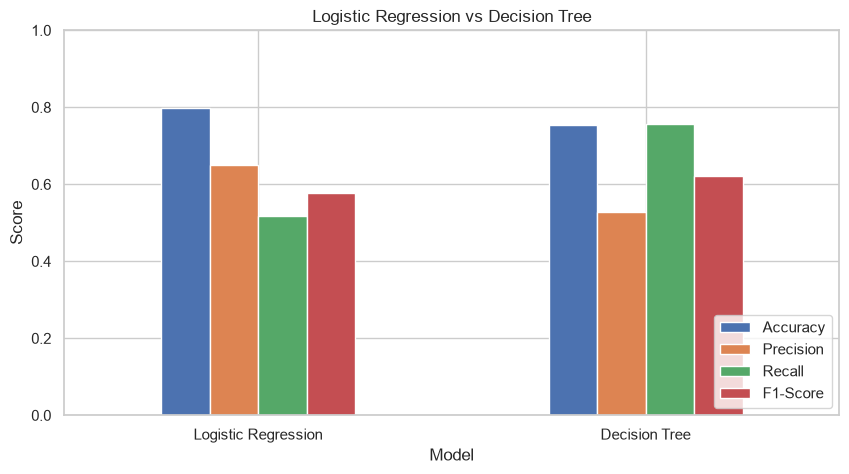

In [145]:
# comparison graph
model_comparison.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-Score"]
].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Logistic Regression vs Decision Tree")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.show()

In [146]:
# random forest 
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),

    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_split=5,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

random_forest_model.fit(X_train, y_train)

print("Random Forest Model Training Completed!")

Random Forest Model Training Completed!


In [147]:
y_pred_rf = random_forest_model.predict(X_test)

print(y_pred_rf[:20])

[0 1 0 0 0 1 1 0 0 1 0 0 0 1 0 0 0 1 0 0]


In [148]:
# model evalution
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("Random Forest Accuracy:",
      accuracy_score(y_test, y_pred_rf))

print("Random Forest Precision:",
      precision_score(y_test, y_pred_rf))

print("Random Forest Recall:",
      recall_score(y_test, y_pred_rf))

print("Random Forest F1 Score:",
      f1_score(y_test, y_pred_rf))

print("\nClassification Report:\n")

print(classification_report(
    y_test,
    y_pred_rf,
    target_names=["No Churn", "Churn"]
))

Random Forest Accuracy: 0.7636621717530163
Random Forest Precision: 0.5412474849094567
Random Forest Recall: 0.7192513368983957
Random Forest F1 Score: 0.6176808266360505

Classification Report:

              precision    recall  f1-score   support

    No Churn       0.88      0.78      0.83      1035
       Churn       0.54      0.72      0.62       374

    accuracy                           0.76      1409
   macro avg       0.71      0.75      0.72      1409
weighted avg       0.79      0.76      0.77      1409



In [149]:
# random forest ROC-AUC
from sklearn.metrics import roc_auc_score

y_prob_rf = random_forest_model.predict_proba(X_test)[:, 1]

rf_auc = roc_auc_score(y_test, y_prob_rf)

print("Random Forest ROC-AUC:", rf_auc)

Random Forest ROC-AUC: 0.8345630215195432


In [150]:
model_comparison = pd.concat([
    model_comparison,
    pd.DataFrame({
        "Model": ["Random Forest"],
        "Accuracy": [accuracy_score(y_test, y_pred_rf)],
        "Precision": [precision_score(y_test, y_pred_rf)],
        "Recall": [recall_score(y_test, y_pred_rf)],
        "F1-Score": [f1_score(y_test, y_pred_rf)]
    })
], ignore_index=True)

print(model_comparison)

                 Model  Accuracy  Precision    Recall  F1-Score
0  Logistic Regression  0.798439   0.651007  0.518717  0.577381
1        Decision Tree  0.755145   0.527002  0.756684  0.621295
2        Random Forest  0.763662   0.541247  0.719251  0.617681


In [ ]:
# XGboost : scale_pos_weight
no_churn = (y_train == 0).sum()
churn = (y_train == 1).sum()

scale_weight = no_churn / churn

print("No Churn:", no_churn)
print("Churn:", churn)
print("Scale Positive Weight:", scale_weight)

No Churn: 4139
Churn: 1495
Scale Positive Weight: 2.768561872909699


In [156]:
print(type(preprocessor))
print(X_train.shape)
print(y_train.shape)
print(scale_weight)

<class 'sklearn.compose._column_transformer.ColumnTransformer'>
(5634, 21)
(5634,)
2.768561872909699


In [162]:
# model ko train krana
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline

xgb_model = Pipeline(steps=[
    ("preprocessor", preprocessor),

    ("classifier", XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale_weight,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

xgb_model.fit(X_train, y_train)

print("XGBoost Model Training Completed!")



XGBoost Model Training Completed!


In [ ]:
# prediction
y_pred_xgb = xgb_model.predict(X_test)

print("XGBoost Predictions:")
print(y_pred_xgb[:20])

XGBoost Predictions:
[0 1 0 1 0 1 1 0 0 1 1 0 0 1 0 0 0 1 0 0]


In [164]:
# model evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

print("XGBoost Accuracy:",
      accuracy_score(y_test, y_pred_xgb))

print("XGBoost Precision:",
      precision_score(y_test, y_pred_xgb))

print("XGBoost Recall:",
      recall_score(y_test, y_pred_xgb))

print("XGBoost F1 Score:",
      f1_score(y_test, y_pred_xgb))

print("XGBoost ROC-AUC:",
      roc_auc_score(y_test, y_prob_xgb))

print("\nClassification Report:")

print(classification_report(
    y_test,
    y_pred_xgb,
    target_names=["No Churn", "Churn"]
))

XGBoost Accuracy: 0.7508871540099361
XGBoost Precision: 0.5210237659963437
XGBoost Recall: 0.7620320855614974
XGBoost F1 Score: 0.6188925081433225
XGBoost ROC-AUC: 0.8396664858301687

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.90      0.75      0.81      1035
       Churn       0.52      0.76      0.62       374

    accuracy                           0.75      1409
   macro avg       0.71      0.75      0.72      1409
weighted avg       0.80      0.75      0.76      1409



In [166]:
import pandas as pd

final_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "XGBoost"
    ],

    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_xgb)
    ],

    "Precision": [
        precision_score(y_test, y_pred),
        precision_score(y_test, y_pred_dt),
        precision_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_xgb)
    ],

    "Recall": [
        recall_score(y_test, y_pred),
        recall_score(y_test, y_pred_dt),
        recall_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_xgb)
    ],

    "F1-Score": [
        f1_score(y_test, y_pred),
        f1_score(y_test, y_pred_dt),
        f1_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_xgb)
    ],

    "ROC-AUC": [
        roc_auc_score(y_test, logistic_model.predict_proba(X_test)[:, 1]),
        roc_auc_score(y_test, decision_tree_model.predict_proba(X_test)[:, 1]),
        roc_auc_score(y_test, random_forest_model.predict_proba(X_test)[:, 1]),
        roc_auc_score(y_test, xgb_model.predict_proba(X_test)[:, 1])
    ]
})

print(final_comparison.round(4))

                 Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
0  Logistic Regression    0.7984     0.6510  0.5187    0.5774   0.8421
1        Decision Tree    0.7551     0.5270  0.7567    0.6213   0.8326
2        Random Forest    0.7637     0.5412  0.7193    0.6177   0.8346
3              XGBoost    0.7509     0.5210  0.7620    0.6189   0.8397


In [167]:
# best model indentify
best_model = final_comparison.loc[
    final_comparison["F1-Score"].idxmax()
]

print("Best Model:", best_model["Model"])
print("Best F1-Score:", best_model["F1-Score"])
print("Best Recall:", best_model["Recall"])
print("Best ROC-AUC:", best_model["ROC-AUC"])

Best Model: Decision Tree
Best F1-Score: 0.6212952799121844
Best Recall: 0.7566844919786097
Best ROC-AUC: 0.8326345294375985


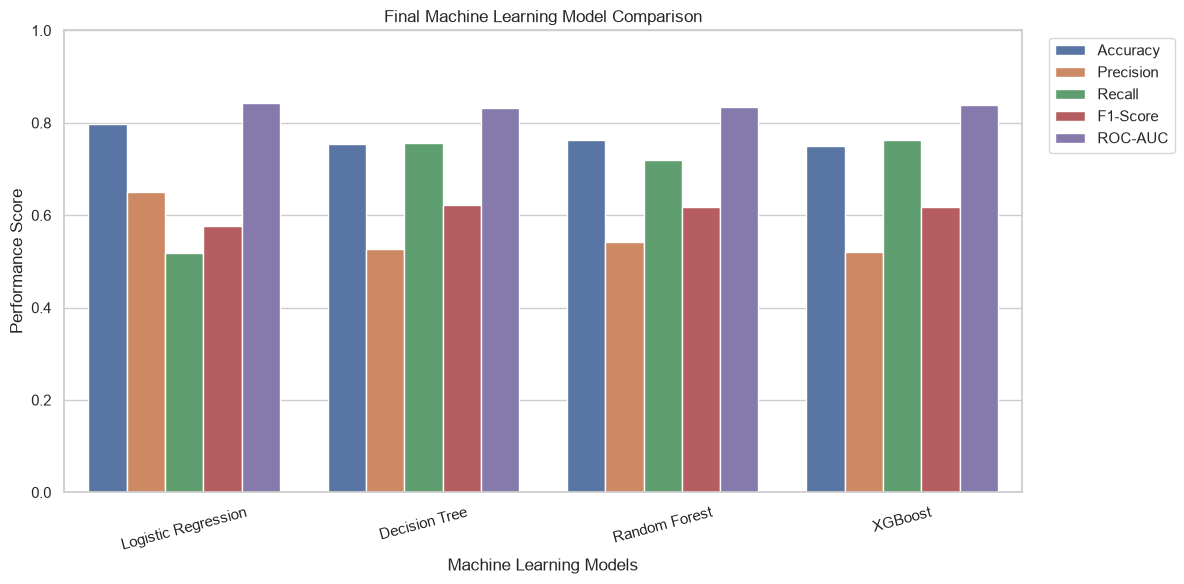

In [168]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

final_plot = final_comparison.melt(
    id_vars="Model",
    var_name="Metric",
    value_name="Score"
)

sns.barplot(
    data=final_plot,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Final Machine Learning Model Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Performance Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [169]:
print("CUSTOMER CHURN PREDICTION - FINAL RESULTS")
print("------------------------------------------")

print("Total Customers:", len(df))
print("Training Customers:", len(X_train))
print("Testing Customers:", len(X_test))

print("\nBest Performing Model:")
print(best_model["Model"])

print("\nBest F1-Score:", round(best_model["F1-Score"], 4))
print("Best Recall:", round(best_model["Recall"], 4))
print("Best ROC-AUC:", round(best_model["ROC-AUC"], 4))

print("\nProject Completed Successfully!")

CUSTOMER CHURN PREDICTION - FINAL RESULTS
------------------------------------------
Total Customers: 7043
Training Customers: 5634
Testing Customers: 1409

Best Performing Model:
Decision Tree

Best F1-Score: 0.6213
Best Recall: 0.7567
Best ROC-AUC: 0.8326

Project Completed Successfully!
